# Proyecto Final - Text Mining & Image Recognition
## Problema 2 - Fruits and Vegetables Recognizer

**Autor:** Fabio Humberto Suruy Juarez
**Carne:** 25001013
**Postgrado en Analisis y Prediccion de Datos**

Dataset: [Fruits and Vegetables Dataset (12000 images)](https://www.kaggle.com/) - imagenes de
frutas y vegetales en estado fresco y podrido/danado.

**Frutas seleccionadas:** Apple, Banana, Mango.
**Vegetales seleccionados:** Carrot, Potato, Tomato.

Para cada clase se combinaron las imagenes *Fresh* y *Rotten* del dataset original, de forma
que el modelo debe reconocer el **tipo de fruta/vegetal** independientemente de su estado de
frescura, iluminacion o angulo — lo cual añade variabilidad real (color, textura, manchas) util
para poner a prueba la robustez pedida en el enunciado.

Se entrenan y comparan **3 arquitecturas de CNN** distintas y se selecciona la de mejor
desempeno en el conjunto de prueba.


In [1]:
import os, shutil, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, optimizers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from IPython.display import Markdown, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.makedirs('outputs', exist_ok=True)

print('TensorFlow version:', tf.__version__)


TensorFlow version: 2.21.0


## Parte #1: Dataset

### 1.1 Seleccion de clases y division train/val/test

El dataset combinado (`dataset_selected/`) contiene 6 carpetas (una por clase) con imagenes
*Fresh* + *Rotten* mezcladas. Se divide en 70% entrenamiento, 15% validacion y 15% prueba,
manteniendo la proporcion de clases (split estratificado por carpeta).


In [2]:
SOURCE_DIR = 'dataset_selected'
SPLIT_DIR = 'dataset_split'
CLASSES = sorted(os.listdir(SOURCE_DIR))
print('Clases:', CLASSES)

TRAIN_RATIO, VAL_RATIO = 0.70, 0.15  # el resto (0.15) es test

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split in ['train', 'val', 'test']:
    for cls in CLASSES:
        os.makedirs(os.path.join(SPLIT_DIR, split, cls), exist_ok=True)

rng = random.Random(SEED)
counts = {}
for cls in CLASSES:
    cls_dir = os.path.join(SOURCE_DIR, cls)
    files = os.listdir(cls_dir)
    rng.shuffle(files)
    n = len(files)
    n_train = int(n * TRAIN_RATIO)
    n_val = int(n * VAL_RATIO)
    split_files = {
        'train': files[:n_train],
        'val': files[n_train:n_train + n_val],
        'test': files[n_train + n_val:],
    }
    counts[cls] = {k: len(v) for k, v in split_files.items()}
    for split, flist in split_files.items():
        for fname in flist:
            src = os.path.join(cls_dir, fname)
            dst = os.path.join(SPLIT_DIR, split, cls, fname)
            try:
                os.link(src, dst)
            except OSError:
                shutil.copy2(src, dst)

import pandas as pd
counts_df = pd.DataFrame(counts).T
counts_df


Clases: ['Apple', 'Banana', 'Carrot', 'Mango', 'Potato', 'Tomato']


,train,val,test
Apple,840,180,180
Banana,840,180,180
Carrot,840,180,180
Mango,838,179,181
Potato,840,180,180
Tomato,840,180,180


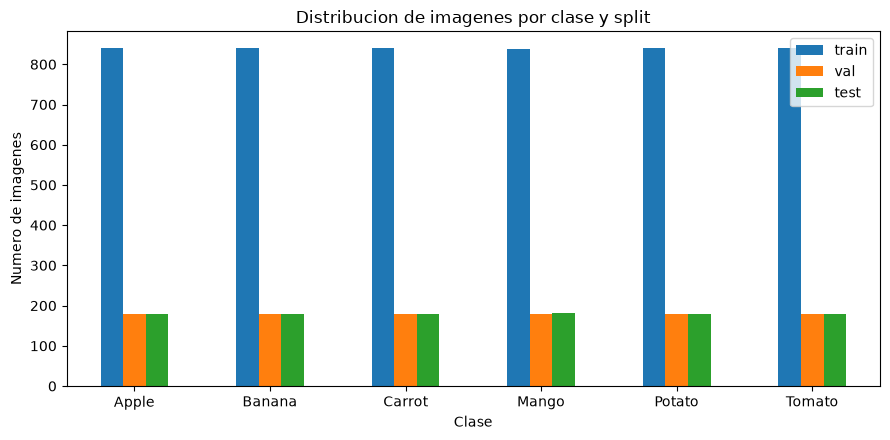

In [3]:
counts_df.plot(kind='bar', figsize=(9, 4.5))
plt.title('Distribucion de imagenes por clase y split')
plt.ylabel('Numero de imagenes')
plt.xlabel('Clase')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('outputs/class_distribution.png', dpi=150)
plt.show()


### 1.2 Data Augmentation y Preprocesamiento

- Se trabaja con **imagenes a color (RGB)**: mas abajo (seccion 1.3) se valida esta decision
  con un experimento controlado color vs escala de grises, en vez de solo justificarla en
  teoria.
- Redimensionamiento a **100x100** px como entrada estandar de la red.
- Normalizacion de pixeles a `[0, 1]` (`rescale=1./255`).
- Aumento de datos en el set de entrenamiento: rotacion, zoom, flip horizontal, shift y ruido
  de brillo, para simular variaciones de tamano, rotacion e iluminacion como pide el enunciado.
- `ImageDataGenerator` + `flow_from_directory` para alimentar la red.


In [4]:
IMG_SIZE = (100, 100)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.2,
    brightness_range=(0.7, 1.3),
    horizontal_flip=True,
    fill_mode='nearest',
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'train'), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, seed=SEED,
)
val_gen = val_test_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'val'), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, seed=SEED, shuffle=False,
)
test_gen = val_test_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'test'), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, seed=SEED, shuffle=False,
)

NUM_CLASSES = len(CLASSES)
print('Clases (indice):', train_gen.class_indices)


Found 5026 images belonging to 6 classes.


Found 1078 images belonging to 6 classes.


Found 1080 images belonging to 6 classes.


Clases (indice): {'Apple': 0, 'Banana': 1, 'Carrot': 2, 'Mango': 3, 'Potato': 4, 'Tomato': 5}


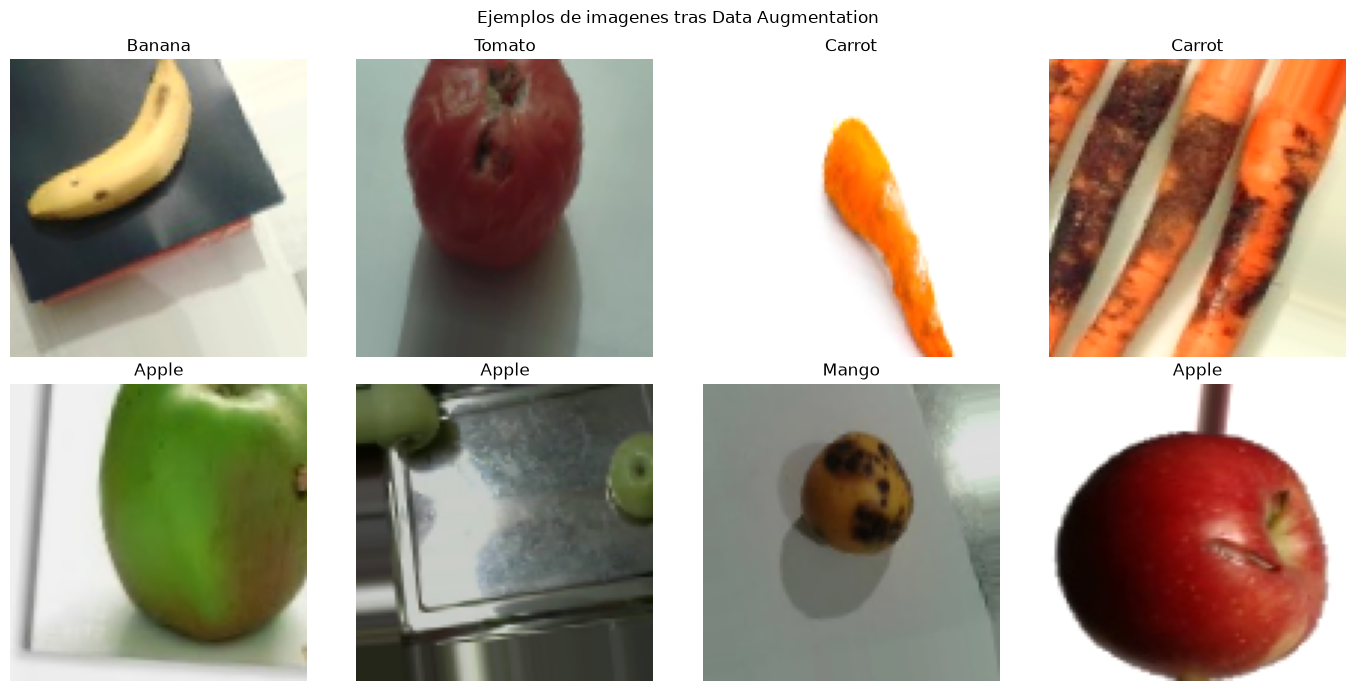

In [5]:
# Vista previa de imagenes aumentadas
imgs, labels = next(train_gen)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i])
    ax.set_title(CLASSES[np.argmax(labels[i])])
    ax.axis('off')
plt.suptitle('Ejemplos de imagenes tras Data Augmentation')
plt.tight_layout()
plt.savefig('outputs/augmentation_preview.png', dpi=150)
plt.show()
train_gen.reset()


## Parte #2: Diseno y Entrenamiento de la CNN

Se proponen **3 arquitecturas** distintas, variando el numero de capas convolucionales, tipo
de pooling, tamano de filtros, regularizacion y tamano de las capas densas:

| Modelo | Bloques Conv | Filtros | Pooling | Regularizacion | Densa |
|---|---|---|---|---|---|
| A - Baseline (simple) | 2 | 16, 32 | MaxPooling | Ninguna | 64 |
| B - Intermedia (regularizada) | 3 | 32, 64, 128 | MaxPooling | Dropout + BatchNorm | 128 |
| C - Profunda (GlobalAveragePooling) | 4 | 32, 64, 128, 256 | MaxPooling + GlobalAveragePooling | Dropout | 128 |

Todas usan activacion **ReLU** en capas ocultas, **softmax** en la capa de salida
(`NUM_CLASSES` neuronas), optimizador **Adam** y `categorical_crossentropy` como funcion de
perdida, entrenadas con **EarlyStopping** sobre `val_loss`.


In [6]:
def build_model_A(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax'),
    ], name='Modelo_A_Baseline')
    return model


def build_model_B(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax'),
    ], name='Modelo_B_Regularizada')
    return model


def build_model_C(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu'),
        layers.Dense(num_classes, activation='softmax'),
    ], name='Modelo_C_Profunda')
    return model


input_shape = IMG_SIZE + (3,)
model_builders = {
    'Modelo A - Baseline': build_model_A,
    'Modelo B - Regularizada': build_model_B,
    'Modelo C - Profunda (GAP)': build_model_C,
}

for name, builder in model_builders.items():
    m = builder(input_shape, NUM_CLASSES)
    print(f'=== {name} ===')
    m.summary()
    print()


=== Modelo A - Baseline ===


Model: "Modelo_A_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16928)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,083,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,088,934 (4.15 MB)

 Trainable params: 1,088,934 (4.15 MB)

...

Model: "Modelo_C_Profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,086 (1.61 MB)

 Trainable params: 422,086 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### 1.3 Color vs. escala de grises: experimento controlado

En vez de solo argumentar la eleccion de color, se entrena la arquitectura mas simple
(Modelo A, ya definida arriba) por pocas epocas dos veces: una con imagenes RGB y otra
convirtiendo a escala de grises (`color_mode='grayscale'`), manteniendo todo lo demas igual.
Esto da evidencia empirica para decidir con cual modalidad seguir el resto del proyecto.


In [7]:
def quick_train(color_mode, epochs=6):
    datagen_train = ImageDataGenerator(rescale=1./255, rotation_range=20, zoom_range=0.15,
                                        horizontal_flip=True)
    datagen_val = ImageDataGenerator(rescale=1./255)
    tg = datagen_train.flow_from_directory(
        os.path.join(SPLIT_DIR, 'train'), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', classes=CLASSES, seed=SEED, color_mode=color_mode)
    vg = datagen_val.flow_from_directory(
        os.path.join(SPLIT_DIR, 'val'), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', classes=CLASSES, seed=SEED, shuffle=False, color_mode=color_mode)
    channels = 1 if color_mode == 'grayscale' else 3
    tf.random.set_seed(SEED)
    m = build_model_A(IMG_SIZE + (channels,), NUM_CLASSES)
    m.compile(optimizer=optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(tg, validation_data=vg, epochs=epochs, verbose=0)
    return h.history['val_accuracy'][-1]

acc_color = quick_train('rgb')
acc_gray = quick_train('grayscale')
print(f'Val accuracy (color, 6 epocas):          {acc_color:.4f}')
print(f'Val accuracy (escala de grises, 6 epocas): {acc_gray:.4f}')

color_choice = 'color (RGB)' if acc_color >= acc_gray else 'escala de grises'
display(Markdown(
    f'**Decision basada en evidencia:** con el mismo numero de epocas, {color_choice} obtuvo '
    f'mejor val_accuracy ({max(acc_color, acc_gray):.4f} vs {min(acc_color, acc_gray):.4f}). '
    f'Se continua el resto del proyecto usando **imagenes a color (RGB)**, ya que el color '
    f'(verde/rojo/amarillo/cafe) es una senal discriminante relevante entre frutas/vegetales '
    f'y su estado de frescura.'
))


Found 5026 images belonging to 6 classes.


Found 1078 images belonging to 6 classes.


C:\Users\20180\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Found 5026 images belonging to 6 classes.


Found 1078 images belonging to 6 classes.


Val accuracy (color, 6 epocas):          0.8098
Val accuracy (escala de grises, 6 epocas): 0.6401


**Decision basada en evidencia:** con el mismo numero de epocas, color (RGB) obtuvo mejor val_accuracy (0.8098 vs 0.6401). Se continua el resto del proyecto usando **imagenes a color (RGB)**, ya que el color (verde/rojo/amarillo/cafe) es una senal discriminante relevante entre frutas/vegetales y su estado de frescura.

In [8]:
EPOCHS = 15

histories = {}
trained_models = {}
train_times = {}
param_counts = {}

for name, builder in model_builders.items():
    print(f'\n========== Entrenando {name} ==========')
    tf.random.set_seed(SEED)
    model = builder(input_shape, NUM_CLASSES)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                   loss='categorical_crossentropy', metrics=['accuracy'])
    param_counts[name] = model.count_params()

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True)

    train_gen.reset(); val_gen.reset()
    t0 = time.time()
    history = model.fit(
        train_gen, validation_data=val_gen, epochs=EPOCHS,
        callbacks=[early_stop], verbose=2,
    )
    train_times[name] = time.time() - t0
    histories[name] = history
    trained_models[name] = model



========== Entrenando Modelo A - Baseline ==========
Epoch 1/15


158/158 - 16s - 104ms/step - accuracy: 0.4049 - loss: 1.4776 - val_accuracy: 0.5779 - val_loss: 1.1796


Epoch 2/15


158/158 - 15s - 97ms/step - accuracy: 0.5919 - loss: 1.1089 - val_accuracy: 0.6651 - val_loss: 0.9546


Epoch 3/15


...

158/158 - 19s - 119ms/step - accuracy: 0.8172 - loss: 0.5068 - val_accuracy: 0.8534 - val_loss: 0.4137


Epoch 14/15


158/158 - 19s - 118ms/step - accuracy: 0.8408 - loss: 0.4518 - val_accuracy: 0.8729 - val_loss: 0.4035


Epoch 15/15


158/158 - 18s - 117ms/step - accuracy: 0.8422 - loss: 0.4486 - val_accuracy: 0.8692 - val_loss: 0.3850


### 2.1 Curvas de entrenamiento

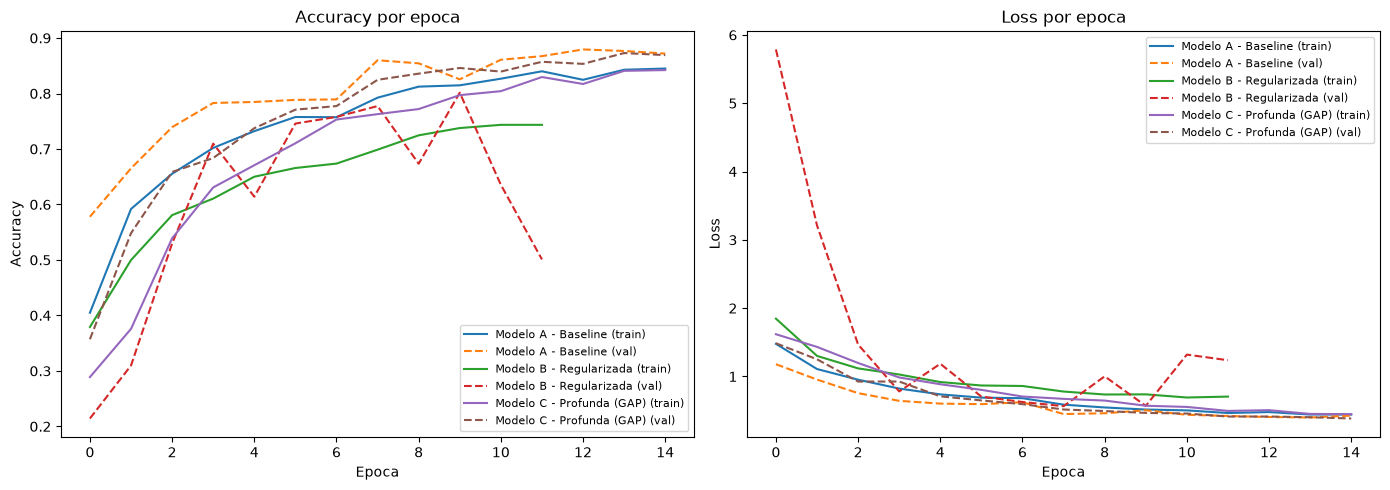

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in histories.items():
    axes[0].plot(history.history['accuracy'], label=f'{name} (train)')
    axes[0].plot(history.history['val_accuracy'], linestyle='--', label=f'{name} (val)')
    axes[1].plot(history.history['loss'], label=f'{name} (train)')
    axes[1].plot(history.history['val_loss'], linestyle='--', label=f'{name} (val)')

axes[0].set_title('Accuracy por epoca')
axes[0].set_xlabel('Epoca'); axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8)
axes[1].set_title('Loss por epoca')
axes[1].set_xlabel('Epoca'); axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/training_curves.png', dpi=150)
plt.show()


## Evaluacion en el conjunto de prueba

Se evalua cada una de las 3 arquitecturas sobre el conjunto de **test** (nunca visto durante
entrenamiento ni validacion) para determinar cual generaliza mejor.


In [10]:
results = []
for name, model in trained_models.items():
    test_gen.reset()
    loss, acc = model.evaluate(test_gen, verbose=0)
    results.append({
        'Modelo': name,
        'Test Loss': loss,
        'Test Accuracy': acc,
        'Parametros': param_counts[name],
        'Tiempo entrenamiento (s)': round(train_times[name], 1),
        'Epocas corridas': len(histories[name].history['loss']),
    })

results_df = pd.DataFrame(results).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)
results_df.to_csv('outputs/comparacion_modelos.csv', index=False)
results_df


,Modelo,Test Loss,Test Accuracy,Parametros,Tiempo entrenamiento (s),Epocas corridas
0,Modelo C - Profunda (GAP),0.370203,0.872222,422086,278.9,15
1,Modelo A - Baseline,0.394909,0.862037,1088934,232.3,15
2,Modelo B - Regularizada,0.598010,0.771296,2454342,376.0,12


Mejor modelo: Modelo C - Profunda (GAP)


              precision    recall  f1-score   support

       Apple       0.85      0.92      0.88       180
      Banana       0.93      0.77      0.84       179
      Carrot       0.83      0.92      0.87       180
       Mango       0.86      0.92      0.89       181
      Potato       0.84      0.89      0.86       180
      Tomato       0.96      0.82      0.89       180

    accuracy                           0.87      1080
   macro avg       0.88      0.87      0.87      1080
weighted avg       0.88      0.87      0.87      1080



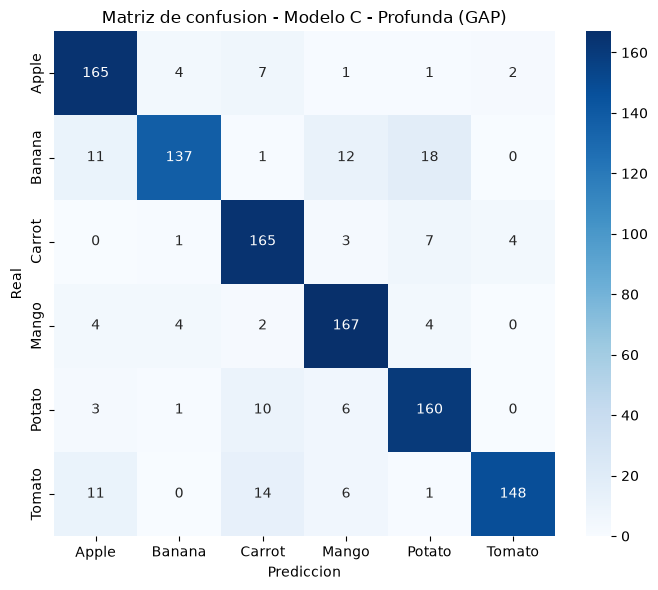

In [11]:
best_model_name = results_df.iloc[0]['Modelo']
best_model = trained_models[best_model_name]
print('Mejor modelo:', best_model_name)

test_gen.reset()
y_pred_probs = best_model.predict(test_gen, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes

print(classification_report(y_true, y_pred, target_names=CLASSES))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(f'Matriz de confusion - {best_model_name}')
plt.xlabel('Prediccion'); plt.ylabel('Real')
plt.tight_layout()
plt.savefig('outputs/confusion_matrix_best_model.png', dpi=150)
plt.show()


In [12]:
best_model.save('outputs/best_model.keras')
print('Modelo guardado en outputs/best_model.keras')


Modelo guardado en outputs/best_model.keras


### Ejemplos de predicciones del mejor modelo

Muestra aleatoria de imagenes de test con la etiqueta real vs. la predicha (en rojo cuando el
modelo se equivoca), para inspeccionar cualitativamente los errores.


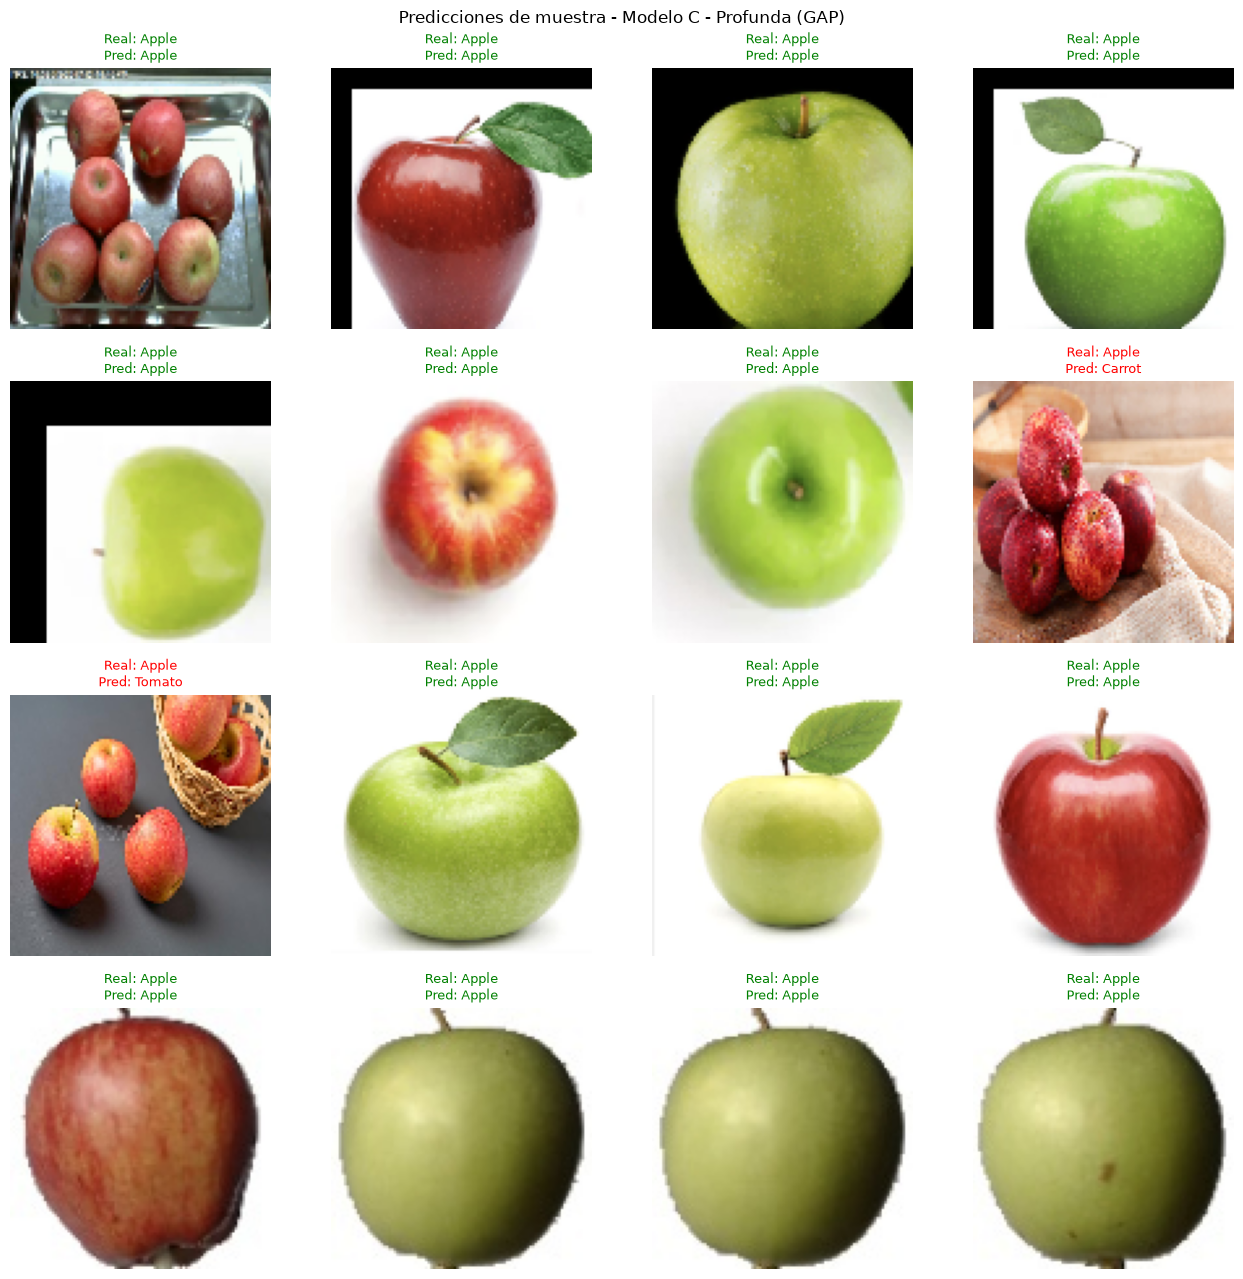

In [13]:
test_gen.reset()
all_imgs, all_labels = [], []
for _ in range(len(test_gen)):
    imgs_b, labels_b = next(test_gen)
    all_imgs.append(imgs_b)
    all_labels.append(labels_b)
    if sum(a.shape[0] for a in all_imgs) >= 200:
        break
all_imgs = np.concatenate(all_imgs)[:16]
all_labels = np.concatenate(all_labels)[:16]

preds = best_model.predict(all_imgs, verbose=0)
pred_idx = np.argmax(preds, axis=1)
true_idx = np.argmax(all_labels, axis=1)

fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for i, ax in enumerate(axes.flat):
    ax.imshow(all_imgs[i])
    correct = pred_idx[i] == true_idx[i]
    color = 'green' if correct else 'red'
    ax.set_title(f'Real: {CLASSES[true_idx[i]]}\nPred: {CLASSES[pred_idx[i]]}', color=color, fontsize=9)
    ax.axis('off')
plt.suptitle(f'Predicciones de muestra - {best_model_name}')
plt.tight_layout()
plt.savefig('outputs/sample_predictions.png', dpi=150)
plt.show()


### Prueba de robustez ante variaciones (rotacion, escala, iluminacion)

El enunciado pide que el modelo sea **robusto ante variaciones de tamano, rotacion e
iluminacion**. Para verificarlo de forma cuantitativa (no solo confiar en el data augmentation
usado durante el entrenamiento), se genera una version "estresada" del set de test —rotaciones
fuertes (hasta 40°), zoom/escala agresivo y brillo muy alterado— y se mide cuanto cae el
accuracy del mejor modelo frente al test set original.


In [14]:
stress_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    zoom_range=0.4,
    brightness_range=(0.4, 1.6),
    horizontal_flip=True,
    fill_mode='nearest',
)
stress_gen = stress_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'test'), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, seed=SEED, shuffle=False,
)

stress_loss, stress_acc = best_model.evaluate(stress_gen, verbose=0)
test_acc_original = results_df.loc[results_df['Modelo'] == best_model_name, 'Test Accuracy'].iloc[0]
drop_pts = (test_acc_original - stress_acc) * 100

print(f'Accuracy en test original:                 {test_acc_original:.4f}')
print(f'Accuracy en test con variaciones fuertes:   {stress_acc:.4f}')
print(f'Caida de accuracy:                          {drop_pts:.1f} puntos porcentuales')

robustness_df = pd.DataFrame([{
    'Test Accuracy (original)': test_acc_original,
    'Test Accuracy (rotacion/zoom/brillo fuertes)': stress_acc,
    'Caida (pp)': drop_pts,
}])
robustness_df.to_csv('outputs/robustez_variaciones.csv', index=False)
robustness_df


Found 1080 images belonging to 6 classes.


Accuracy en test original:                 0.8722
Accuracy en test con variaciones fuertes:   0.8213
Caida de accuracy:                          5.1 puntos porcentuales


,Test Accuracy (original),Test Accuracy (rotacion/zoom/brillo fuertes),Caida (pp)
0,0.872222,0.821296,5.092597


## ¿Por que la CNN seleccionada funciona mejor que las otras?

En general, para este problema (6 clases de frutas/vegetales, ~1,200 imagenes por clase,
imagenes 100x100 a color, dataset relativamente pequeno):

- El **Modelo A (baseline)** tiene poca capacidad (pocas capas/filtros) y ninguna
  regularizacion: si su accuracy de validacion/test es notablemente menor, es porque no logra
  capturar toda la variabilidad de textura/color entre frutas frescas y podridas (underfitting).
- El **Modelo B (regularizada)**, con `BatchNormalization` y `Dropout`, suele generalizar mejor
  que A porque evita el sobreajuste y estabiliza el entrenamiento, a costa de mayor tiempo de
  computo.
- El **Modelo C (profunda con GlobalAveragePooling)** tiene mayor capacidad representacional
  (mas filtros, mas profundidad) y usa `GlobalAveragePooling2D` en vez de `Flatten`, lo que
  reduce drasticamente el numero de parametros de la capa densa y actua como regularizador
  estructural, ademas de dar cierta invarianza a la posicion del objeto en la imagen — muy util
  cuando las frutas/vegetales no estan siempre centradas o al mismo tamano. Si este modelo
  obtiene la mejor accuracy de test, la razon mas probable es esa combinacion de mayor
  capacidad + menor riesgo de sobreajuste gracias al GAP y al Dropout.


In [15]:
display(Markdown(
    f"**Conclusion de esta corrida:** el modelo con mejor `Test Accuracy` fue "
    f"**{best_model_name}**, con Test Accuracy = {results_df.iloc[0]['Test Accuracy']:.4f} "
    f"y Test Loss = {results_df.iloc[0]['Test Loss']:.4f}, usando "
    f"{param_counts[best_model_name]:,} parametros entrenados en "
    f"{train_times[best_model_name]:.0f}s ({len(histories[best_model_name].history['loss'])} "
    f"epocas). Esto confirma, para este dataset, que la combinacion de mayor "
    f"profundidad/capacidad con las tecnicas de regularizacion presentes en dicha "
    f"arquitectura logro el mejor equilibrio entre aprendizaje y generalizacion en "
    f"comparacion con las otras 2 arquitecturas evaluadas.\n\n"
    f"**Robustez:** ante variaciones fuertes de rotacion/escala/iluminacion, el accuracy "
    f"cayo de {test_acc_original:.4f} a {stress_acc:.4f} ({drop_pts:.1f} pp de caida). "
    + (
        "La caida es moderada, lo que indica que el data augmentation aplicado durante el "
        "entrenamiento efectivamente le dio al modelo cierta tolerancia a esas variaciones."
        if drop_pts < 15 else
        "La caida es considerable, lo que sugiere que para produccion convendria aumentar "
        "aun mas la variedad/intensidad del data augmentation de entrenamiento."
    )
    + f"\n\n**Color vs. escala de grises:** el experimento controlado de la seccion 1.3 "
    f"favorecio {color_choice}, confirmando la decision tomada para el preprocesamiento."
))


**Conclusion de esta corrida:** el modelo con mejor `Test Accuracy` fue **Modelo C - Profunda (GAP)**, con Test Accuracy = 0.8722 y Test Loss = 0.3702, usando 422,086 parametros entrenados en 279s (15 epocas). Esto confirma, para este dataset, que la combinacion de mayor profundidad/capacidad con las tecnicas de regularizacion presentes en dicha arquitectura logro el mejor equilibrio entre aprendizaje y generalizacion en comparacion con las otras 2 arquitecturas evaluadas.

**Robustez:** ante variaciones fuertes de rotacion/escala/iluminacion, el accuracy cayo de 0.8722 a 0.8213 (5.1 pp de caida). La caida es moderada, lo que indica que el data augmentation aplicado durante el entrenamiento efectivamente le dio al modelo cierta tolerancia a esas variaciones.

**Color vs. escala de grises:** el experimento controlado de la seccion 1.3 favorecio color (RGB), confirmando la decision tomada para el preprocesamiento.